# Lab 06: ekonometrika dengan data Indonesia

**Durasi:** 90 menit

Semua lab sebelumnya memakai data simulasi dari halaman kuliah. Lab ini
memakai data Indonesia yang sungguhan, diunduh dari sumber terbuka:

| File | Isi | Sumber |
|---|---|---|
| `ihsg_harian.csv` | IHSG harian, 2019 sampai 2026 | Yahoo Finance |
| `ihsg_panjang.csv` | IHSG harian, 1990 sampai 2026 | Yahoo Finance |
| `kurs_harian.csv` | Kurs USD/IDR harian, 2019 sampai 2026 | ECB via Frankfurter |
| `idn_kurs_tahunan.csv` | Kurs tahunan, 1967 sampai 2025 | World Bank |
| `idn_inflasi_bulanan.csv` | Inflasi bulanan, 1969 sampai 2025 | BPS via OECD/FRED |
| `idn_makro_tahunan.csv` | Inflasi, PDB, pengangguran, kurs, 2000 sampai 2025 | World Bank |
| `asean_panel.csv` | 10 negara ASEAN, 2000 sampai 2025 | World Bank |
| `provinsi_2021.csv` | 34 provinsi: PDRB, IPM, kemiskinan, dll | kompilasi BPS |

Semua file dibaca dari salinan GitHub melalui `URL_DATA`. Cara memperbarui datanya ada
di akhir lab ini.



**Posisi dalam alur workshop.** Lab 00 memakai data Indonesia untuk EDA.
Lab 01 sampai 05 melatih pemodelan pada contoh terbimbing. Lab 06 menerapkan
alur tersebut pada data pasar keuangan, makro, panel ASEAN, dan provinsi.

## Persiapan: alamat data



**Alur sesi:** kita menerapkan analisis pada data panel atau data Indonesia. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah arti skala, periode, dan keterbatasan pola yang terlihat.

Jalankan contoh terbimbing sampai hasilnya muncul, kemudian lengkapi sel latihan yang masih berupa komentar.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")

Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
%pip install "linearmodels==7.1" "arch==8.0.0" -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})

plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

## 1. GARCH pada IHSG asli

Inilah momen yang ditunggu: memakai data nyata yang volatilitasnya
benar-benar mengelompok. Bandingkan hasilnya dengan data simulasi di
Sesi 06 yang murni ARCH (beta = 0).



<!-- kamus_variabel:ihsg_harian.csv -->

### Kenali data: IHSG harian

**Data:** `data/ihsg_harian.csv`. **Satu baris:** satu hari perdagangan di pasar saham.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Date` | Tanggal hari perdagangan. | Tanggal YYYY-MM-DD | Penanda waktu |
| `Close` | Nilai penutupan Indeks Harga Saham Gabungan (IHSG). | Poin indeks | Deret yang dianalisis |
| `High` | Nilai indeks tertinggi pada hari tersebut. | Poin indeks | Informasi perdagangan |
| `Low` | Nilai indeks terendah pada hari tersebut. | Poin indeks | Informasi perdagangan |
| `Open` | Nilai indeks saat pembukaan hari perdagangan. | Poin indeks | Informasi perdagangan |
| `Volume` | Volume perdagangan yang dilaporkan penyedia data untuk ticker indeks. | Satuan pelaporan Yahoo; bukan rupiah atau poin indeks | Informasi perdagangan |

IHSG adalah indeks, sehingga Close = 6.000 berarti 6.000 poin, bukan Rp6.000. Return dihitung dari perubahan Close. Nilai Volume nol tidak otomatis menunjukkan tidak ada perdagangan; cakupan pelaporan mengikuti penyedia.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ret` | Return logaritmik harian: 100 × (ln Close hari ini - ln Close sebelumnya). | Persen log-return |

Sumber definisi: [rujukan data](https://finance.yahoo.com/quote/%5EJKSE/history/).


In [4]:
ihsg = pd.read_csv(URL_DATA + "ihsg_harian.csv", parse_dates=["Date"])

ihsg.head()

,Date,Close,High,Low,Open,Volume
0,2019-01-02,6181.174805,6205.895020,6164.833984,6197.871094,52797800
1,2019-01-03,6221.009766,6221.009766,6176.151855,6176.151855,72166700
2,2019-01-04,6274.540039,6274.540039,6200.854004,6211.096191,80858100
3,2019-01-07,6287.224121,6354.757812,6287.224121,6317.625977,90278300
4,2019-01-08,6262.847168,6316.240234,6251.375977,6292.263184,90537400


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

Jumlah observasi: 1866
Rentang: 2019-01-03 sampai 2026-09-29


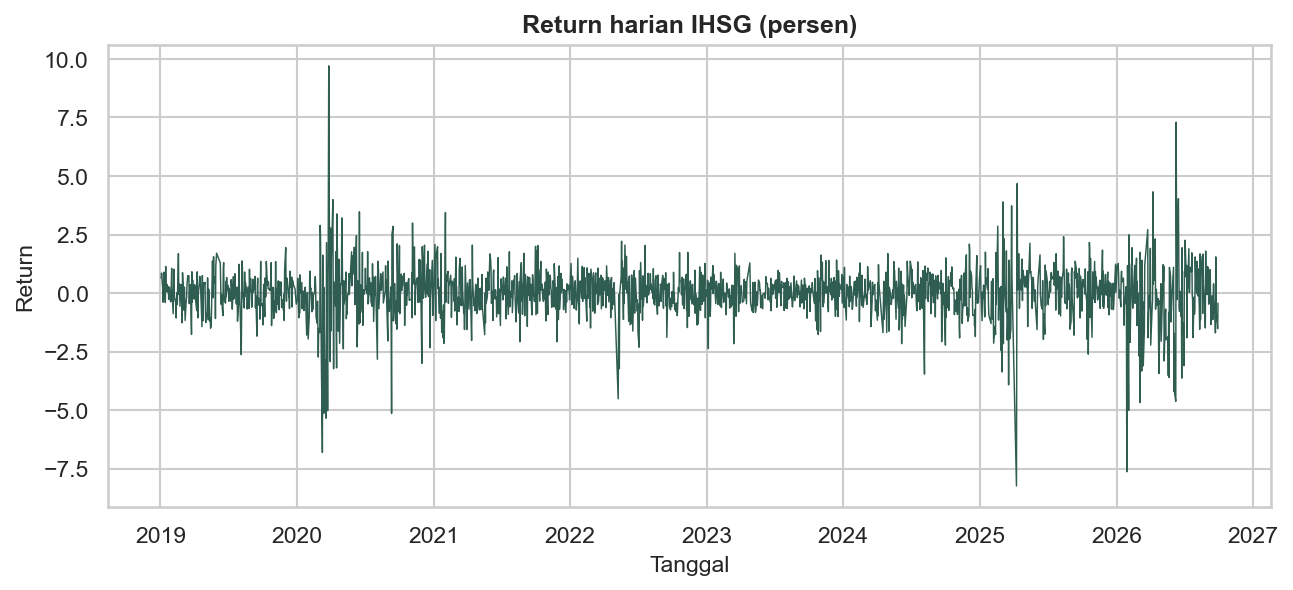

In [5]:
# Return logaritmik harian dalam persen: selisih log dikali 100
ihsg["ret"] = 100 * np.log(ihsg["Close"]).diff()
ihsg = ihsg.dropna()

print("Jumlah observasi:", len(ihsg))
print("Rentang:", ihsg["Date"].min().date(), "sampai", ihsg["Date"].max().date())

plt.figure(figsize=(10, 4))
plt.plot(ihsg["Date"], ihsg["ret"], lw=0.7)
plt.title("Return harian IHSG (persen)")
plt.xlabel("Tanggal")
plt.ylabel("Return")
plt.show()

**Baca grafik sebelum lanjut:** Baca waktu dari kiri ke kanan dan cocokkan satuan sumbu Y. Cari perubahan tingkat, tren, dan periode bergejolak sebelum menafsirkan hasil model.

Perhatikan lonjakan besar di sekitar Maret 2020 (COVID), lalu
bandingkan dengan lonjakan pada 2025 dan 2026 yang lebih pendek.
Sekarang uji efek ARCH, seperti di Sesi 06.



In [6]:
from statsmodels.stats.diagnostic import het_arch

# Regresi mean sederhana, hanya untuk mengambil residualnya
sampel_model_mean = ihsg[["ret"]].dropna()
X_model_mean = pd.DataFrame({"konstanta": 1}, index=sampel_model_mean.index)
y_model_mean = sampel_model_mean["ret"]

model_mean = DummyRegressor(strategy="mean")
model_mean.fit(X_model_mean, y_model_mean)

prediksi_model_mean = pd.Series(
    model_mean.predict(X_model_mean), index=y_model_mean.index
)
residu_model_mean = y_model_mean - prediksi_model_mean
# [1] = p-value dari uji ARCH-LM
p_arch = het_arch(residu_model_mean, nlags=5)[1]
print(f"ARCH LM test: p-value = {p_arch:.3e}")
print("p jauh di bawah 0,05: efek ARCH sangat kuat.")

ARCH LM test: p-value = 2.459e-53
p jauh di bawah 0,05: efek ARCH sangat kuat.


C:\Users\MyPC PRO\Documents\ekonometrika\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [7]:
from arch import arch_model

hasil = arch_model(ihsg["ret"], vol="Garch", p=1, q=1).fit(disp="off")
print(hasil.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                    ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2540.50
Distribution:                  Normal   AIC:                           5089.00
Method:            Maximum Likelihood   BIC:                           5111.12
                                        No. Observations:                 1866
Date:                Sun, Oct 25 2026   Df Residuals:                     1865
Time:                        20:33:46   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu             0.0253  1.985e-02      1.276      0.202 

### Cocokkan periode gejolak dengan volatilitas hasil model

Gunakan tanggal yang sama pada kedua panel agar lonjakan return dapat
dibandingkan dengan simpangan baku bersyarat dari GARCH.

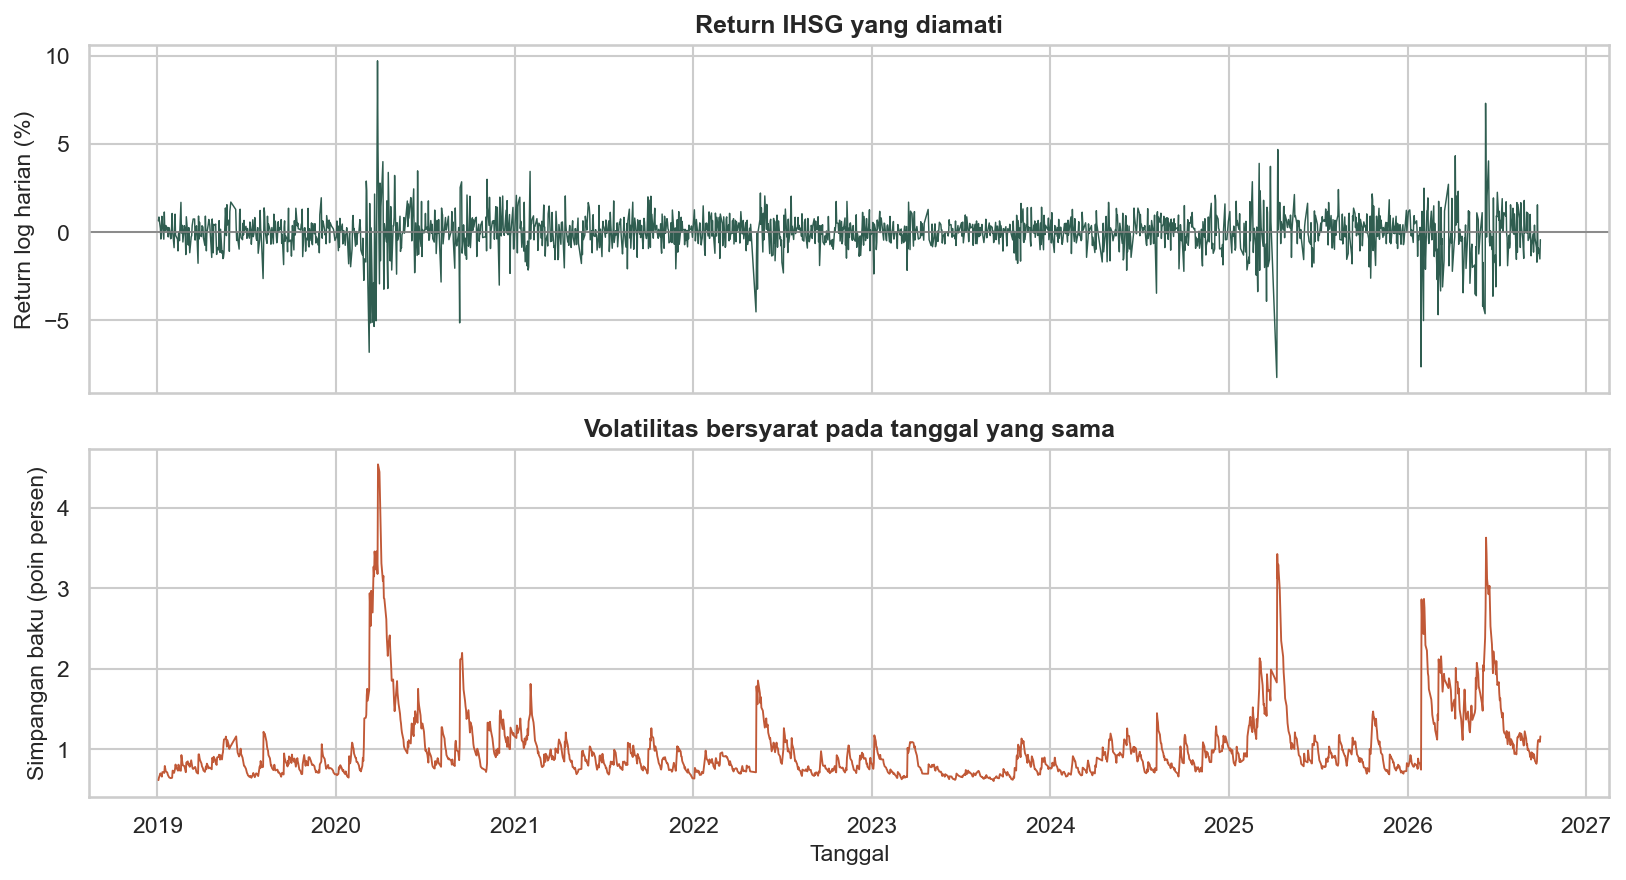

In [8]:
volatilitas_ihsg = hasil.conditional_volatility / hasil.scale
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(ihsg["Date"], ihsg["ret"], color="#2F5D50", linewidth=0.7)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set(ylabel="Return log harian (%)", title="Return IHSG yang diamati")
axes[1].plot(ihsg["Date"], volatilitas_ihsg, color="#C15937", linewidth=0.9)
axes[1].set(xlabel="Tanggal", ylabel="Simpangan baku (poin persen)", title="Volatilitas bersyarat pada tanggal yang sama")
plt.tight_layout()
plt.show()

**Cara membaca:** panel atas dapat bernilai positif atau negatif,
sedangkan simpangan baku di bawah selalu tidak negatif. Cari periode dengan
lonjakan berkelompok dan lihat apakah volatilitas tetap tinggi beberapa
waktu sesudahnya. Volatilitas tidak memprediksi arah naik atau turun IHSG.

In [9]:
alpha = hasil.params["alpha[1]"]
beta = hasil.params["beta[1]"]
print(f"alpha = {alpha:.4f}  (reaksi terhadap guncangan baru)")
print(f"beta  = {beta:.4f}  (persistensi volatilitas lama)")
print(f"alpha + beta = {alpha + beta:.4f}")
print()
print("Bandingkan dengan data simulasi Sesi 6: beta = 0, persistensi 0,81.")
print("Di data nyata, persistensi mendekati 0,95: guncangan hilang perlahan.")

alpha = 0.1310  (reaksi terhadap guncangan baru)
beta  = 0.8198  (persistensi volatilitas lama)
alpha + beta = 0.9508

Bandingkan dengan data simulasi Sesi 6: beta = 0, persistensi 0,81.
Di data nyata, persistensi mendekati 0,95: guncangan hilang perlahan.


### Aplikasi sederhana: Value at Risk

VaR 5 persen harian: berapa kerugian yang hanya terlampaui pada 5 persen
hari terburuk. Ini cara cepat memakainya untuk manajemen risiko.



In [10]:
var95 = np.percentile(ihsg["ret"], 5)
print(f"VaR 5% harian: {var95:.3f} persen")
print(
    f"Untuk portofolio Rp 10 juta, risiko harian sekitar Rp {abs(var95) / 100 * 10_000_000:,.0f}"
)

VaR 5% harian: -1.691 persen
Untuk portofolio Rp 10 juta, risiko harian sekitar Rp 169,101


### Coba sendiri (5 menit)

Dari volatilitas bersyarat GARCH IHSG tadi (`hasil.conditional_volatility`),
cari tanggal dengan sigma tertinggi dan bandingkan dengan rata-ratanya.

Tulis di sel di bawah, baru buka jawabannya.



In [11]:
# Tulis kode Anda di sini

<details><summary>Lihat jawaban</summary>

Sigma tertinggi = 4,54 pada 27 Maret 2020 (puncak COVID), sementara
rata-rata seluruh periode hanya 1,01. Artinya hari itu volatilitas
4,5 kali lebih besar dari hari biasa.

</details>



## 2. Panel ASEAN dengan data asli

`asean_panel.csv` berisi 10 negara ASEAN, 2000 sampai 2025: pertumbuhan
PDB, FDI (persen dari PDB), angkatan kerja, inflasi, dan pengangguran.
Kita uji: apakah FDI berhubungan dengan pertumbuhan ekonomi?



<!-- kamus_variabel:asean_panel.csv -->

### Kenali data: Panel negara ASEAN dari World Bank

**Data:** `data/asean_panel.csv`. **Satu baris:** satu negara pada satu tahun.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Negara` | Kode negara ISO tiga huruf; misalnya IDN = Indonesia, MYS = Malaysia. | Kode negara | Penanda, bukan besaran ekonomi |
| `Tahun` | Tahun kalender pengamatan. | Tahun | Penanda waktu |
| `PDB_Growth` | Laju pertumbuhan tahunan PDB riil (Produk Domestik Bruto). | Persen per tahun; NY.GDP.MKTP.KD.ZG | Target pertumbuhan pada model panel |
| `Inflasi` | Kenaikan tahunan indeks harga konsumen. | Persen per tahun; FP.CPI.TOTL.ZG | Y atau X sesuai model |
| `Pengangguran` | Pengangguran sebagai bagian dari total angkatan kerja, estimasi model ILO. | Persen angkatan kerja; SL.UEM.TOTL.ZS | X: penjelas |
| `Kurs_USD` | Kurs resmi rata-rata periode: mata uang lokal untuk memperoleh satu dolar AS. | Mata uang lokal per US$1; PA.NUS.FCRF | X: penjelas |
| `FDI` | Arus masuk bersih investasi asing langsung relatif terhadap PDB. | Persen PDB; BX.KLT.DINV.WD.GD.ZS | X: penjelas |
| `Angkatan_Kerja` | Penduduk yang bekerja atau aktif mencari pekerjaan. | Orang; SL.TLF.TOTL.IN | X: penjelas |

Kurs_USD memakai mata uang negara masing-masing, sehingga IDN berarti rupiah/US$ dan MYS berarti ringgit/US$. FDI = 5 berarti 5% PDB; perubahan dari 5 ke 6 adalah 1 poin persen.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ln_angkatan_kerja` | Logaritma alami jumlah angkatan kerja. | Skala logaritma |

Sumber definisi: [rujukan data](https://databank.worldbank.org/source/world-development-indicators).


In [12]:
panel = pd.read_csv(URL_DATA + "asean_panel.csv")
panel["ln_angkatan_kerja"] = np.log(panel["Angkatan_Kerja"])
print("Negara:", sorted(panel["Negara"].unique()))
panel.head()

Negara: ['BRN', 'IDN', 'KHM', 'LAO', 'MMR', 'MYS', 'PHL', 'SGP', 'THA', 'VNM']


,Negara,Tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,FDI,Angkatan_Kerja,ln_angkatan_kerja
0,BRN,2000,3.474676,1.558152,5.530,1.723963,8.364135,155602,11.955057
1,BRN,2001,1.466061,0.595890,5.558,1.791723,0.995622,160781,11.987798
2,BRN,2002,3.961439,-2.314972,5.652,1.790588,3.626543,165377,12.015983
3,BRN,2003,3.583429,0.300000,5.743,1.742183,1.727478,169865,12.042759
4,BRN,2004,0.104538,0.814224,5.847,1.690228,1.313418,174224,12.068097


In [13]:
from linearmodels.panel import PanelOLS, RandomEffects

data_panel = panel.set_index(["Negara", "Tahun"])
y = data_panel["PDB_Growth"]
X = data_panel[["FDI", "ln_angkatan_kerja"]]

cem = PanelOLS(y, sm.add_constant(X)).fit(cov_type="clustered", cluster_entity=True)
fem = PanelOLS(y, X, entity_effects=True).fit(cov_type="clustered", cluster_entity=True)
rem = RandomEffects(y, sm.add_constant(X)).fit(
    cov_type="clustered", cluster_entity=True
)

print("=== CEM ===")
print(cem.params.round(4))
print("\n=== FEM ===")
print(fem.params.round(4))
print("\n=== REM ===")
print(rem.params.round(4))

=== CEM ===
const               -4.9936
FDI                  0.0920
ln_angkatan_kerja    0.5953
Name: parameter, dtype: float64

=== FEM ===
FDI                  0.2111
ln_angkatan_kerja   -5.9426
Name: parameter, dtype: float64

=== REM ===
const                6.0210
FDI                  0.0724
ln_angkatan_kerja   -0.0702
Name: parameter, dtype: float64


### Amati pertumbuhan antarnegara sebelum memasang model panel

Setiap garis mewakili negara. Grafik tetap memakai tahun pengamatan, bukan nomor urut baris.

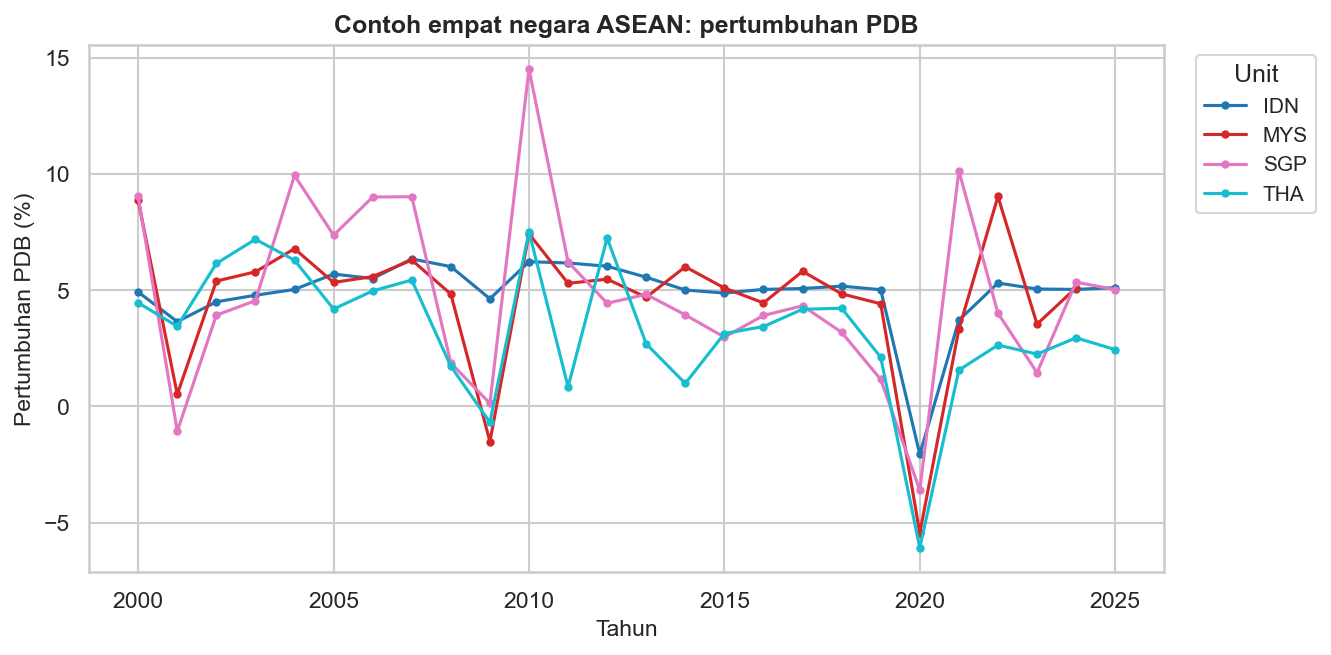

In [14]:
tabel_garis = panel.pivot(index="Tahun", columns="Negara", values="PDB_Growth")
ax = tabel_garis[["IDN", "MYS", "SGP", "THA"]].plot(colormap="tab10", figsize=(9, 4.5), marker="o", markersize=3)
ax.set_xlabel("Tahun")
ax.set_ylabel("Pertumbuhan PDB (%)")
ax.set_title("Contoh empat negara ASEAN: pertumbuhan PDB")
ax.legend(title="Unit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** Gerakan bersama dapat berkaitan dengan kejadian pada tahun yang sama. Bandingkan pola ini dengan peran efek individu dan waktu pada model panel yang dipakai. Beberapa pasangan negara–tahun tidak tersedia; celah pada seri bukan nilai nol. Grafik dibatasi pada Indonesia, Malaysia, Singapura, dan Thailand agar mudah dibaca; model panel tetap memakai seluruh negara yang tersedia pada data.

### Uji Chow dan Hausman



In [15]:
print("Uji Chow (CEM vs FEM):")
print(fem.f_pooled)

# Hausman klasik memakai kovarians unadjusted pada sampel yang sama.
# Hasil clustered di atas tetap dipakai untuk pelaporan koefisien dan SE.
fem_uji = PanelOLS(y, X, entity_effects=True).fit()
rem_uji = RandomEffects(y, sm.add_constant(X)).fit()

# sigmamore menyamakan dasar varians galat kedua model memakai estimasi REM.
hausman = rem_uji.hausman(fem_uji, sigmamore=True)
print(hausman)

Uji Chow (CEM vs FEM):
Pooled F-statistic
H0: Effects are zero
Statistic: 17.5653
P-value: 0.0000
Distributed: F(9,239)
Hausman specification test
H0: No systematic difference in coefficients between models
Statistic: 24.4747
P-value: 0.0000
Distributed: chi2(2)

Coefficients (b0: consistent under H0 and H1, b1: efficient under H0)
                         b0        b1     b0-b1  Std. Err.
FDI                0.211110  0.072352  0.138758   0.039771
ln_angkatan_kerja -5.942635 -0.070198 -5.872437   1.187874


### Membaca hasil

- Uji Chow menolak CEM: efek khas tiap negara nyata, jadi harus
  diperhitungkan.
- Hausman menolak REM (p di bawah 0,05), jadi keputusannya FEM.
- Di FEM, koefisien FDI sekitar +0,21 dan signifikan. Artinya, DI DALAM
  satu negara, tahun dengan FDI lebih tinggi cenderung tumbuh lebih
  cepat. Di CEM koefisiennya hanya +0,09 dan tidak signifikan, karena
  estimasi itu mencampur perbedaan antarnegara dengan perubahan dalam
  negara.
- Koefisien angkatan kerja negatif di FEM. Ini korelasi within, bukan
  sebab akibat: periode dengan pertumbuhan angkatan kerja cepat
  (misalnya setelah krisis) justru bersamaan dengan pertumbuhan PDB
  yang lambat.



### Coba sendiri (5 menit)

Lihat p-value Hausman pada bagian 2. Model mana yang dipakai,
dan apa artinya secara ekonomi untuk FDI?

Tulis di sel di bawah, baru buka jawabannya.



In [16]:
# Tulis jawaban singkat Anda di sini

<details><summary>Lihat jawaban</summary>

p < 0,05, jadi FEM. Artinya perbandingan antarnegara saja tidak cukup;
yang dibaca adalah perubahan DI DALAM satu negara. Koefisien FDI +
0,21 berarti kenaikan FDI 1 poin persen berhubungan dengan
pertumbuhan sekitar 0,21 poin persen lebih tinggi dalam negara yang sama.

</details>



## 3. Makro Indonesia tahunan

Data 26 tahun, 2000 sampai 2025. Kita uji hubungan inflasi dan
pengangguran, dua indikator yang selalu diberitakan bersama.



<!-- kamus_variabel:idn_makro_tahunan.csv -->

### Kenali data: Makroekonomi Indonesia tahunan

**Data:** `data/idn_makro_tahunan.csv`. **Satu baris:** satu tahun kalender untuk Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `negara` | Kode negara; IDN menunjukkan Indonesia. | Kode ISO negara | Penanda, bukan besaran ekonomi |
| `tahun` | Tahun kalender pengamatan. | Tahun | Penanda waktu |
| `PDB_Growth` | Laju pertumbuhan tahunan PDB riil (Produk Domestik Bruto). | Persen per tahun; NY.GDP.MKTP.KD.ZG | Target pertumbuhan pada model panel |
| `Inflasi` | Kenaikan tahunan indeks harga konsumen. | Persen per tahun; FP.CPI.TOTL.ZG | Y atau X sesuai model |
| `Pengangguran` | Pengangguran sebagai bagian dari total angkatan kerja, estimasi model ILO. | Persen angkatan kerja; SL.UEM.TOTL.ZS | X: penjelas |
| `Kurs_USD` | Kurs resmi rata-rata periode: mata uang lokal untuk memperoleh satu dolar AS. | Mata uang lokal per US$1; PA.NUS.FCRF | X: penjelas |
| `Angkatan_Kerja` | Penduduk yang bekerja atau aktif mencari pekerjaan. | Orang; SL.TLF.TOTL.IN | X: penjelas |

Kurs_USD untuk Indonesia bersatuan rupiah per US$1. Inflasi dan pertumbuhan adalah laju persen, bukan nilai level harga atau level PDB.

Sumber definisi: [rujukan data](https://databank.worldbank.org/source/world-development-indicators).


In [17]:
makro = pd.read_csv(URL_DATA + "idn_makro_tahunan.csv")

makro.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [18]:
makro.tail()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
21,IDN,2021,3.702886,1.560079,3.827,14308.143901,135672770
22,IDN,2022,5.307197,4.209465,3.462,14849.853936,139637843
23,IDN,2023,5.048831,3.669387,3.308,15236.884662,143318723
24,IDN,2024,5.032575,2.181513,3.301,15855.448287,145198137
25,IDN,2025,5.108089,1.913334,3.237,16477.865180,147104597


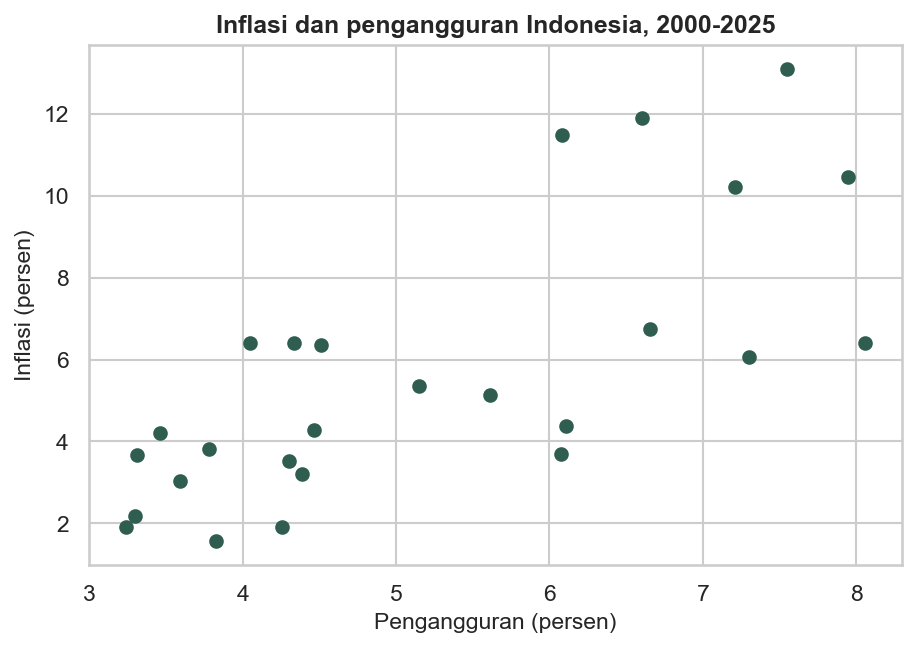

In [19]:
plt.figure(figsize=(7, 4.5))
plt.scatter(makro["Pengangguran"], makro["Inflasi"])
plt.xlabel("Pengangguran (persen)")
plt.ylabel("Inflasi (persen)")
plt.title("Inflasi dan pengangguran Indonesia, 2000-2025")
plt.show()

**Baca grafik sebelum lanjut:** Satu titik mewakili satu pengamatan. Baca nama dan satuan kedua sumbu, lalu jelaskan arah hubungan serta sebaran titik. Pola visual dipakai untuk memahami model berikutnya, bukan sebagai bukti kausal.

In [20]:
sampel_model_makro = makro[["Inflasi", "Pengangguran"]].dropna()
X_model_makro = sampel_model_makro[["Pengangguran"]]
y_model_makro = sampel_model_makro["Inflasi"]

model_makro = LinearRegression()
model_makro.fit(X_model_makro, y_model_makro)

LinearRegression()

### Lihat hasil model: Inflasi tahunan (%)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

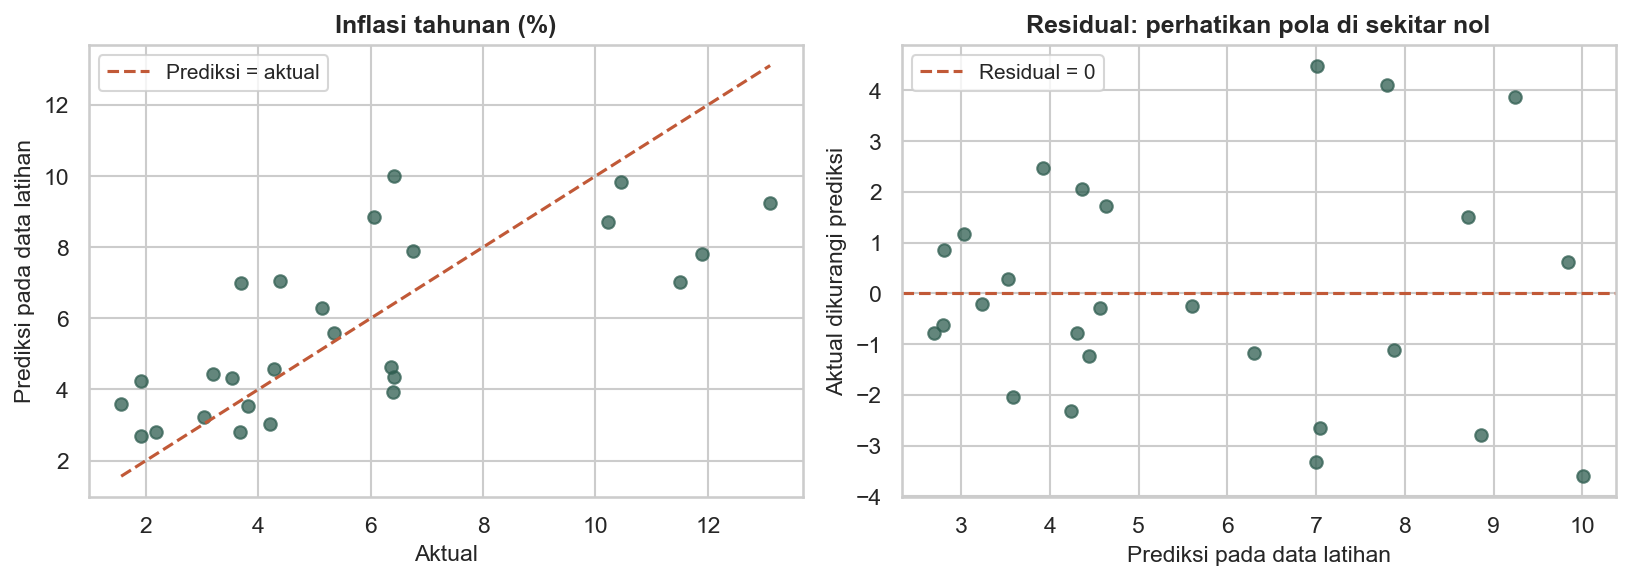

In [21]:
prediksi_visual = model_makro.predict(X_model_makro)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_makro, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_makro.min(), y_model_makro.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Inflasi tahunan (%)")
axes[1].scatter(prediksi_visual, y_model_makro - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [22]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_makro = sm.OLS(
    y_model_makro,
    sm.add_constant(X_model_makro, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_makro.summary())

                            OLS Regression Results                            
Dep. Variable:                Inflasi   R-squared:                       0.535
Model:                            OLS   Adj. R-squared:                  0.516
Method:                 Least Squares   F-statistic:                     27.63
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           2.18e-05
Time:                        20:33:48   Log-Likelihood:                -57.244
No. Observations:                  26   AIC:                             118.5
Df Residuals:                      24   BIC:                             121.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -2.2105      1.565     -1.413   

### Membaca hasil

Koefisiennya positif dan sangat signifikan, kebalikan dari cerita
Phillips curve klasik. Kenapa? Di Indonesia 2000-2025, periode dengan
pengangguran tinggi (2005, 2008, 2020) justru bersamaan dengan inflasi
tinggi karena keduanya didorong krisis, bukan hubungan sebab akibat
langsung. Pelajaran: tanda koefisien harus dibaca dengan konteks sejarah,
bukan sekadar mencocokkan teori.



## 4. Kurs harian: stasioneritas

Data kurs USD/IDR harian dari ECB. Uji ADF di level dan setelah selisih.



<!-- kamus_variabel:kurs_harian.csv -->

### Kenali data: Kurs rupiah harian

**Data:** `data/kurs_harian.csv`. **Satu baris:** satu tanggal tersedianya kurs acuan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Tanggal` | Tanggal kurs acuan tersedia; bukan selalu setiap hari kalender. | Tanggal YYYY-MM-DD | Penanda waktu |
| `Kurs_USD_IDR` | Jumlah rupiah untuk memperoleh satu dolar AS (USD = dolar AS; IDR = rupiah). | Rupiah per US$1 | Deret yang dianalisis |

Seri diambil melalui Frankfurter dari kurs acuan ECB. Perubahan kurs adalah kolom turunan, bukan arti nilai kurs level.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ret_kurs` | Perubahan relatif kurs harian: 100 × (kurs hari ini / kurs sebelumnya - 1). | Persen; positif berarti rupiah melemah |

Sumber definisi: [rujukan data](https://www.frankfurter.dev/).


In [23]:
from statsmodels.tsa.stattools import adfuller

kurs = pd.read_csv(URL_DATA + "kurs_harian.csv", parse_dates=["Tanggal"])

kurs.head()

,Tanggal,Kurs_USD_IDR
0,2018-12-31,14410
1,2019-01-02,14463
2,2019-01-03,14410
3,2019-01-04,14243
4,2019-01-07,14087


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [24]:
print("Jumlah observasi:", len(kurs))
print("ADF di level      : p =", round(adfuller(kurs["Kurs_USD_IDR"])[1], 4))
print(
    "ADF setelah selisih: p =",
    round(adfuller(kurs["Kurs_USD_IDR"].diff().dropna())[1], 4),
)

Jumlah observasi: 1985
ADF di level      : p = 0.7586


ADF setelah selisih: p = 0.0


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_19432\1110848049.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF di level      : p =", round(adfuller(kurs["Kurs_USD_IDR"])[1], 4))
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_19432\1110848049.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  round(adfuller(kurs["Kurs_USD_IDR"].diff().dropna())[1], 4),


### Bedakan tingkat kurs dan perubahan kurs

Persentase perubahan kurs menjawab pertanyaan berbeda dari nilai rupiah per dolar pada suatu tanggal.

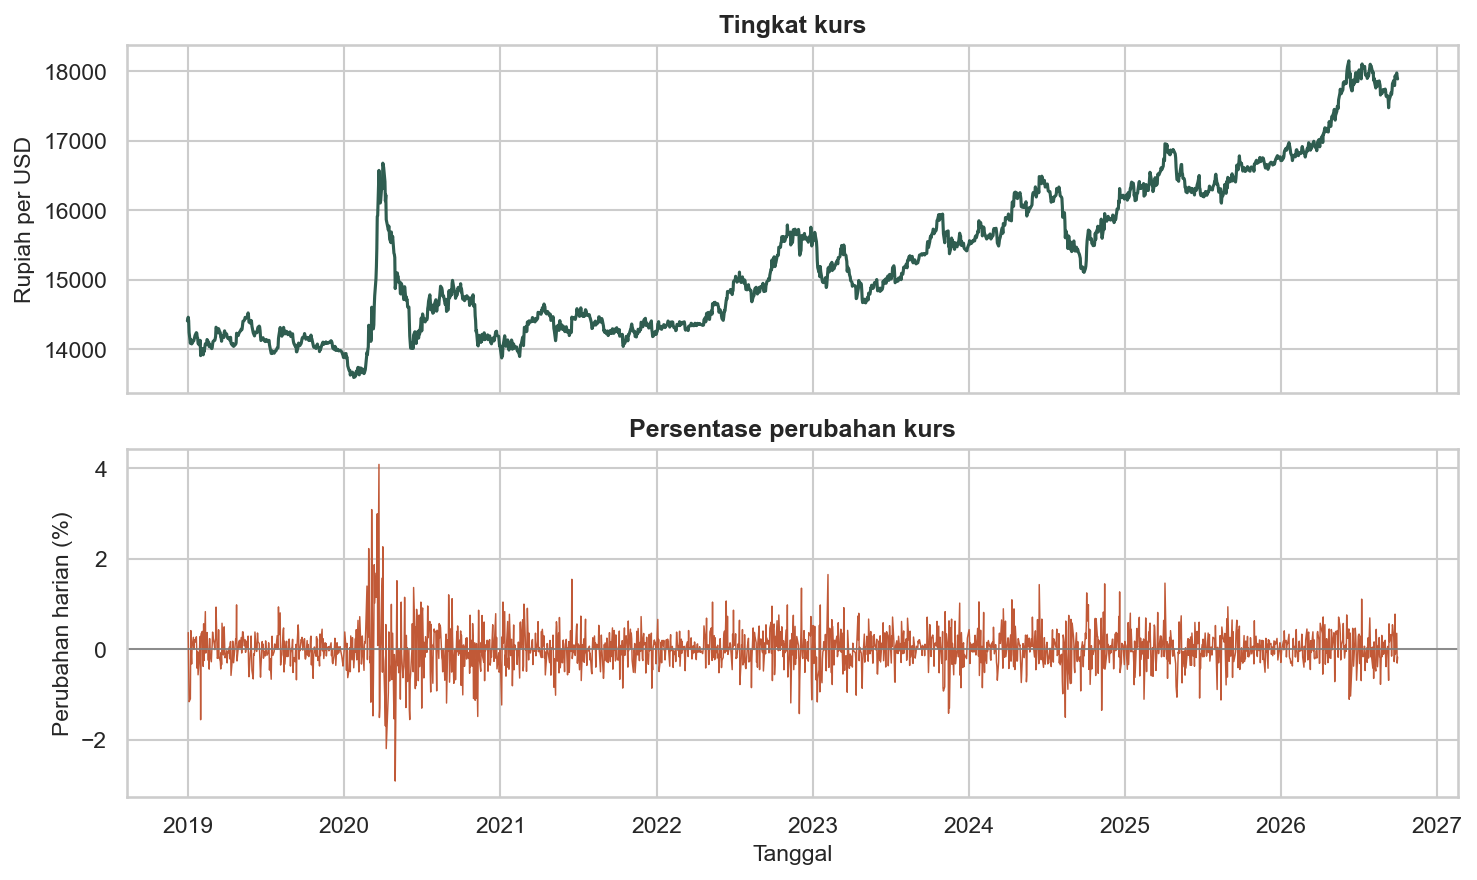

In [25]:
perubahan_kurs = 100 * kurs["Kurs_USD_IDR"].pct_change()
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(kurs["Tanggal"], kurs["Kurs_USD_IDR"])
axes[0].set(ylabel="Rupiah per USD", title="Tingkat kurs")
axes[1].plot(kurs["Tanggal"], perubahan_kurs, color="#C15937", linewidth=0.7)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set(xlabel="Tanggal", ylabel="Perubahan harian (%)", title="Persentase perubahan kurs")
plt.tight_layout()
plt.show()

**Cara membaca:** Seri level dan perubahan mempunyai makna serta pola yang berbeda. Gunakan seri yang sesuai saat membaca uji stasioneritas; gambar belum menggantikan pengujian.

Seperti kurs di Sesi 05: tidak stasioner di level, stasioner setelah
selisih. Ini pola khas nilai tukar.



## 5. Krisis 1997-1998 dalam data asli

Inflasi bulanan Indonesia tersedia sejak 1969, dan kurs tahunan sejak
1967. Keduanya menangkap krisis finansial Asia yang menghantam Indonesia
pada 1997-1998: rupiah melemah dari sekitar 2.900 menjadi 10.000 per
dolar, dan inflasi melonjak.



<!-- kamus_variabel:idn_inflasi_bulanan.csv -->

### Kenali data: IHK dan inflasi Indonesia bulanan

**Data:** `data/idn_inflasi_bulanan.csv`. **Satu baris:** satu bulan kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `tanggal` | Bulan pengamatan; tanggal berfungsi sebagai penanda bulan. | Tanggal YYYY-MM-DD | Penanda waktu |
| `indeks` | Indeks Harga Konsumen (IHK), yaitu ukuran tingkat harga keranjang konsumsi. | Poin indeks; tahun dasar mengikuti seri sumber | Level harga |
| `inflasi_mom` | Persentase perubahan indeks dari bulan sebelumnya (month-on-month). | 100 × (indeks bulan ini / bulan lalu - 1) | Deret yang dianalisis |
| `inflasi_yoy` | Persentase perubahan indeks dari bulan yang sama setahun sebelumnya (year-on-year). | 100 × (indeks bulan ini / indeks 12 bulan lalu - 1) | Deret yang dianalisis |

indeks adalah level, sedangkan inflasi_mom dan inflasi_yoy adalah perubahan persen yang dihitung oleh skrip unduhan. Angka 2 pada kolom inflasi berarti 2%, bukan 0,02%.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `era` | Label pengelompokan periode untuk ringkasan/grafik inflasi. | Kategori periode, bukan variabel inflasi baru |

Sumber definisi: [rujukan data](https://fred.stlouisfed.org/series/IDNCPIALLMINMEI).


In [26]:
inflasi = pd.read_csv(URL_DATA + "idn_inflasi_bulanan.csv", parse_dates=["tanggal"])

inflasi.head()

,tanggal,indeks,inflasi_mom,inflasi_yoy
0,1969-01-01,0.762293,1.666665,35.555542
1,1969-02-01,0.774790,1.639343,25.252521
2,1969-03-01,0.793535,2.419366,24.509816
3,1969-04-01,0.756045,-4.724418,26.041662
4,1969-05-01,0.756045,0.000000,19.801980


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

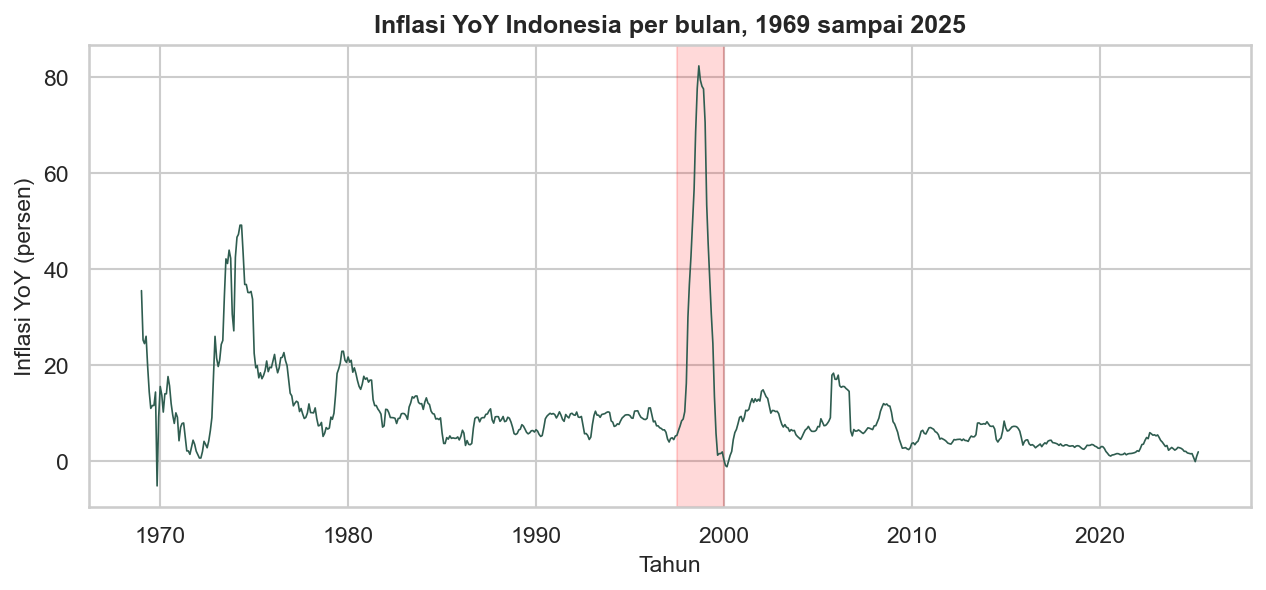

In [27]:
plt.figure(figsize=(10, 4))
plt.plot(inflasi["tanggal"], inflasi["inflasi_yoy"], lw=0.8)
plt.axvspan(
    pd.Timestamp("1997-07-01"), pd.Timestamp("1999-12-31"), color="red", alpha=0.15
)
plt.title("Inflasi YoY Indonesia per bulan, 1969 sampai 2025")
plt.xlabel("Tahun")
plt.ylabel("Inflasi YoY (persen)")
plt.show()

**Baca grafik sebelum lanjut:** Baca waktu dari kiri ke kanan dan cocokkan satuan sumbu Y. Cari perubahan tingkat, tren, dan periode bergejolak sebelum menafsirkan hasil model.

Grafik memakai angka **YoY pada setiap bulan**, yaitu perubahan IHK
terhadap bulan yang sama setahun sebelumnya. Pada berkas ini, puncaknya
sekitar 82,42 persen pada September 1998. Rata-rata dari 12 angka YoY
pada 1998 sekitar 58,01 persen; rata-rata ini berbeda dari puncak grafik.
Pada 2016 sampai 2025, angka tertinggi sekitar 5,95 persen.

In [28]:
# Bentuk kolom era satu langkah per batas tahun. loc berarti memilih baris.
inflasi["era"] = "1970-1979"
inflasi.loc[inflasi["tanggal"] >= "1980-01-01", "era"] = "1980-1996"
inflasi.loc[inflasi["tanggal"] >= "1997-01-01", "era"] = "1997-1999"
inflasi.loc[inflasi["tanggal"] >= "2000-01-01", "era"] = "2000-2019"
inflasi.loc[inflasi["tanggal"] >= "2020-01-01", "era"] = "2020-2025"
periode_analisis = inflasi[inflasi["tanggal"].between("1970-01-01", "2025-12-31")]
# groupby() mengelompokkan baris berdasarkan era, mean() menghitung rata-rata.
rata_per_era = periode_analisis.groupby("era")["inflasi_yoy"].mean()
print(rata_per_era.round(2))

era
1970-1979    16.99
1980-1996     9.24
1997-1999    29.42
2000-2019     6.62
2020-2025     2.60
Name: inflasi_yoy, dtype: float64


In [29]:
print(
    "ADF indeks harga (level)      : p =",
    round(adfuller(inflasi["indeks"].dropna())[1], 4),
)
print(
    "ADF inflasi YoY (sudah transformasi): p =",
    round(adfuller(inflasi["inflasi_yoy"].dropna())[1], 4),
)

ADF indeks harga (level)      : p = 1.0
ADF inflasi YoY (sudah transformasi): p = 0.0002


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_19432\2320549380.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  round(adfuller(inflasi["indeks"].dropna())[1], 4),
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_19432\2320549380.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  round(adfuller(inflasi["inflasi_yoy"].dropna())[1], 4),


Ini pelajaran stasioneritas dengan data asli: indeks harga tidak
stasioner karena selalu naik, tetapi inflasi YoY sudah stasioner karena
kenaikan harga relatif stabil di sekitar levelnya.



<!-- kamus_variabel:idn_kurs_tahunan.csv -->

### Kenali data: Kurs rupiah tahunan

**Data:** `data/idn_kurs_tahunan.csv`. **Satu baris:** satu tahun kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `tahun` | Tahun pengamatan. | Tahun | Penanda waktu |
| `kurs` | Kurs resmi rata-rata satu tahun, rupiah yang diperlukan untuk US$1. | Rupiah per dolar AS | Deret yang dianalisis |

Kurs yang meningkat berarti satu dolar membutuhkan lebih banyak rupiah, sehingga rupiah melemah terhadap dolar.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `pertumbuhan` | Perubahan relatif kurs dari tahun sebelumnya, dikalikan 100. | Persen per tahun |

Sumber definisi: [rujukan data](https://data.worldbank.org/indicator/PA.NUS.FCRF).


In [30]:
kurs_panjang = pd.read_csv(URL_DATA + "idn_kurs_tahunan.csv")

kurs_panjang.head()

,tahun,kurs
0,1967,149.583333
1,1968,296.291667
2,1969,326.000000
3,1970,362.833333
4,1971,391.875000


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [31]:
print(kurs_panjang[kurs_panjang["tahun"].between(1996, 1999)])

kurs_panjang["pertumbuhan"] = 100 * kurs_panjang["kurs"].pct_change()
print("\nPertumbuhan kurs (persen):")
print(
    kurs_panjang[kurs_panjang["tahun"].between(1997, 1999)]
    .round(2)
    .to_string(index=False)
)

    tahun          kurs
29   1996   2342.296292
30   1997   2909.380000
31   1998  10013.622500
32   1999   7855.150000

Pertumbuhan kurs (persen):
 tahun     kurs  pertumbuhan
  1997  2909.38        24.21
  1998 10013.62       244.18
  1999  7855.15       -21.56


Rupiah melemah 24 persen pada 1997 dan 244 persen pada 1998, lalu
menguat 22 persen pada 1999. Untuk analisis deret waktu, lonjakan ini
adalah contoh patahan struktural (structural break) yang sebenarnya,
bukan simulasi.



## 6. Latihan mandiri

**Latihan 1: GARCH pada kurs.** Data `data/kurs_harian.csv`.
- Hitung return harian kurs (persen) dengan `.pct_change()`.
- Estimasi GARCH(1,1) dan laporkan alpha, beta, serta persistensinya.
- Bandingkan dengan IHSG. Mana yang lebih persisten?



In [32]:
# kurs = pd.read_csv(URL_DATA + "kurs_harian.csv", parse_dates=["Tanggal"])
# kurs["ret_kurs"] = 100 * kurs["Kurs_USD_IDR"].pct_change()
# kurs_ret = kurs.dropna()
# ...

**Latihan 2: GARCH jangka panjang.** Data `data/ihsg_panjang.csv` berisi
IHSG sejak 1990, mencakup krisis 1998, krisis global 2008, dan COVID.
- Estimasi GARCH(1,1) pada seluruh periode, lalu bandingkan dengan hasil
  periode 2019-2026 di bagian 1 (persistensi 0,95).
- Coba juga potong periode 1990-1999 saja. Apa yang terjadi pada
  alpha + beta?



<!-- kamus_variabel:ihsg_panjang.csv -->

### Kenali data: IHSG riwayat panjang

**Data:** `data/ihsg_panjang.csv`. **Satu baris:** satu hari perdagangan di pasar saham.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Date` | Tanggal hari perdagangan. | Tanggal YYYY-MM-DD | Penanda waktu |
| `Close` | Nilai penutupan Indeks Harga Saham Gabungan (IHSG). | Poin indeks | Deret yang dianalisis |
| `High` | Nilai indeks tertinggi pada hari tersebut. | Poin indeks | Informasi perdagangan |
| `Low` | Nilai indeks terendah pada hari tersebut. | Poin indeks | Informasi perdagangan |
| `Open` | Nilai indeks saat pembukaan hari perdagangan. | Poin indeks | Informasi perdagangan |
| `Volume` | Volume perdagangan yang dilaporkan penyedia data untuk ticker indeks. | Satuan pelaporan Yahoo; bukan rupiah atau poin indeks | Informasi perdagangan |

IHSG adalah indeks, sehingga Close = 6.000 berarti 6.000 poin, bukan Rp6.000. Return dihitung dari perubahan Close. Nilai Volume nol tidak otomatis menunjukkan tidak ada perdagangan; cakupan pelaporan mengikuti penyedia.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ret` | Return logaritmik harian: 100 × selisih log Close. | Persen log-return |

Sumber definisi: [rujukan data](https://finance.yahoo.com/quote/%5EJKSE/history/).


In [33]:
# panjang = pd.read_csv(URL_DATA + "ihsg_panjang.csv", parse_dates=["Date"])
# panjang["ret"] = 100 * np.log(panjang["Close"]).diff()
# panjang = panjang.dropna()
# ...

**Latihan 3: cross-section provinsi.** Data `data/provinsi_2021.csv`
berisi 34 provinsi dengan indikator sosial ekonomi 2021.
- Regresikan `Kemiskinan` pada `IPM`. Berapa koefisiennya dan apa
  artinya?
- Bandingkan model `IPM ~ PDRB_Kapita` (linear) dengan
  `IPM ~ ln(PDRB_Kapita)` (log). Mana yang lebih cocok? Pakai R kuadrat
  terkoreksi. Perbandingan ini sah karena variabel Y-nya sama (IPM);
  yang berubah hanya bentuk variabel penjelasnya.



<!-- kamus_variabel:provinsi_2021.csv -->

### Kenali data: Indikator 34 provinsi tahun 2021

**Data:** `data/provinsi_2021.csv`. **Satu baris:** satu provinsi pada tahun 2021 dalam kompilasi sumber.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Provinsi` | Nama provinsi yang diamati. | Nama wilayah | Penanda, bukan besaran ekonomi |
| `PDRB_Kapita` | Produk Domestik Regional Bruto per penduduk, ukuran output ekonomi per kapita. | Skala sumber; dipakai sebagai ribu rupiah dalam tutorial | Y atau X sesuai model |
| `IPM` | Indeks Pembangunan Manusia yang merangkum dimensi kesehatan, pendidikan, dan taraf hidup. | Poin indeks, bukan persen | Y atau X sesuai model |
| `Pengangguran` | Tingkat Pengangguran Terbuka (TPT). | Persen angkatan kerja | X: penjelas |
| `Kemiskinan` | Penduduk yang berada di bawah garis kemiskinan. | Persen penduduk | Y: target |
| `AHH_Laki` | Angka Harapan Hidup laki-laki pada kompilasi sumber. | Tahun | Indikator pendamping |
| `AHH_Perempuan` | Angka Harapan Hidup perempuan pada kompilasi sumber. | Tahun | Indikator pendamping |
| `APS_7_12` | Angka Partisipasi Sekolah penduduk umur 7 sampai 12 tahun. | Persen penduduk kelompok umur tersebut | Indikator pendamping |
| `APS_13_15` | Angka Partisipasi Sekolah penduduk umur 13 sampai 15 tahun. | Persen penduduk kelompok umur tersebut | Indikator pendamping |
| `APS_16_18` | Angka Partisipasi Sekolah penduduk umur 16 sampai 18 tahun. | Persen penduduk kelompok umur tersebut | Indikator pendamping |
| `APS_19_23` | Angka Partisipasi Sekolah penduduk umur 19 sampai 23 tahun. | Persen penduduk kelompok umur tersebut | Indikator pendamping |
| `Perokok` | Persentase perokok pada kompilasi data provinsi. | Persen; cakupan umur mengikuti sumber | Indikator pendamping |

Berkas ini adalah kompilasi indikator, bukan tabel metadata lengkap BPS. Cakupan indikator dan skala PDRB perlu diperiksa pada sumber BPS sebelum dipakai untuk riset; barisnya mengikuti 34 provinsi pada tahun 2021.

Sumber definisi: [rujukan data](https://github.com/sainsdataid/dataset/blob/main/Data%2034%20Provinsi%202021.csv).


In [34]:
# prov = pd.read_csv(URL_DATA + "provinsi_2021.csv")
# ...

**Latihan 4: ganti spesifikasi panel.** Ulangi bagian 2 dengan
`PDB_Growth ~ FDI + Inflasi` (tanpa angkatan kerja).
- Apakah uji Hausman masih memilih FEM?
- Apakah kesimpulan tentang FDI berubah? Bandingkan dengan bagian 2
  yang memakai `ln_angkatan_kerja`.



In [35]:
# ...

**Latihan 5: data Anda sendiri.** Buka [panduan sumber data](https://github.com/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/pengajar/README.md#sumber-data-indonesia) di folder utama,
bagian "Sumber data Indonesia". Ada tiga jalur untuk mengambil data
sendiri: World Bank, BPS WebAPI, dan Yahoo Finance. Pilih satu, ambil
data untuk topik yang Anda minati, dan jalankan regresi sederhana.

Untuk memperbarui semua data di folder `data/` sekaligus, jalankan
`python alat_bantu/unduh_data_indonesia.py` di komputer sendiri (butuh
internet).



## Selanjutnya

Lanjutkan ke [praktik regresi harga rumah](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/03_regresi_housing/01_regresi_housing.ipynb), lalu dashboard penutup. [Proyek mini](https://github.com/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/02_latihan/07_proyek_mini.md) dapat dikerjakan sesudah latihan.